# 1. Download dataset từ https://ogb.stanford.edu/docs/nodeprop/#ogbn-mag

In [29]:
!pip3 install ogb torch

In [ ]:
import urllib.request
from tqdm import tqdm
import os

os.makedirs("data", exist_ok=True)
url = "http://snap.stanford.edu/ogb/data/nodeproppred/mag.zip"
save_path = "./data/mag.zip"

urllib.request.urlretrieve(url, save_path)
# chỉ chạy 1 lần download

## 2. Khởi tạo Spark & Đọc Đồ Thị Trích Dẫn (Paper cites Paper)
- **Mục đích:** Đọc danh sách các cạnh trích dẫn giữa các bài báo (`paper -> paper`).
- **Quy ước:** Cột `src` là bài báo đi trích dẫn (source), `dst` là bài báo được trích dẫn (destination).

In [31]:
path = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/relations/paper___cites___paper/edge.csv.gz"

In [32]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

In [33]:
spark = SparkSession.builder.appName("CitationGraph").getOrCreate()
df = spark.read.csv(path, header=False, inferSchema=True).toDF("src", "dst")
print(df.show(5))

+---+------+
|src|   dst|
+---+------+
|  0|    88|
|  0| 27449|
|  0|121051|
|  0|151667|
|  0|308499|
+---+------+
only showing top 5 rows
None


In [34]:
df_clean = df.filter(col("src").isNotNull() & col("dst").isNotNull())
so_bac_vao = df_clean.groupBy("dst").count().orderBy(col("count").desc())
print("Số bậc vào:")
so_bac_vao.show(10)

Số bậc vào:


+------+-----+
|   dst|count|
+------+-----+
|428523| 4744|
|420612| 3215|
|210535| 2265|
|188195| 2217|
|472963| 2196|
|395731| 2048|
|295507| 1939|
|384889| 1690|
|391519| 1633|
|416291| 1517|
+------+-----+
only showing top 10 rows


## 3. Tổng Số Lượng Cạnh Trích Dẫn (Total Citation Edges)
- **Ý nghĩa:** Đếm tổng số liên kết trích dẫn hợp lệ sau khi loại bỏ giá trị Null.

In [35]:
print("Số lượng dòng dữ liệu trích dẫn:", df_clean.count())

Số lượng dòng dữ liệu trích dẫn: 5416271


## 4. Phân Bố Bậc Vào (In-Degree Distribution) & Quy Luật Đuôi Dài (Heavy-Tail)
- **Bậc vào (In-degree):** Số lần bài báo được trích dẫn bởi các bài báo khác.
- **Đặc điểm:** Tuân theo luật lũy thừa (Power-Law) - đại đa số bài báo chỉ có 1-2 trích dẫn, rất ít bài báo có hàng nghìn trích dẫn.

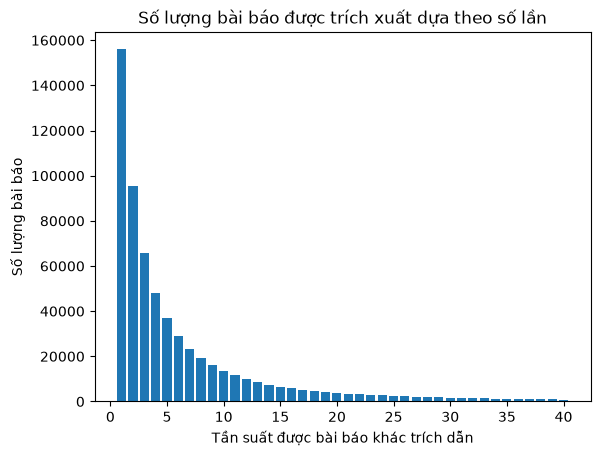

In [36]:
import matplotlib.pyplot as plt 

data = df_clean.groupBy("dst").count().groupBy("count").count().orderBy("count").limit(40).toPandas()
data.columns = ["so_trich_dan", "so_bai_bao"]
plt.bar(data["so_trich_dan"], data["so_bai_bao"])
plt.xlabel("Tần suất được bài báo khác trích dẫn")
plt.ylabel("Số lượng bài báo")
plt.title("Số lượng bài báo được trích xuất dựa theo số lần")
plt.show()

## 5. Phân Chia Tập Dữ Liệu Theo Thời Gian (Time-Split: Train / Valid / Test)
- **Quy ước của Stanford OGB:**
  - `train`: Bài báo xuất bản từ 2010 đến 2017 (629.571 bài).
  - `valid`: Bài báo xuất bản năm 2018 (64.879 bài).
  - `test`: Bài báo xuất bản năm 2019 (41.939 bài).
- **Lưu ý:** Các file này chỉ chứa danh sách `paper_id` (chỉ số dòng từ 0 đến 736.388).

In [37]:
df_train = spark.read.csv("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/split/time/paper/train.csv.gz", header=False).toDF("paper_id")
print(f"Số bài báo tập train (trước 2018): {df_train.count()}")


Số bài báo tập train (trước 2018): 629571


In [38]:
df_train.show(5)

+--------+
|paper_id|
+--------+
|       0|
|       1|
|       2|
|       3|
|       4|
+--------+
only showing top 5 rows


In [39]:
df_valid = spark.read.csv("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/split/time/paper/valid.csv.gz", header=False).toDF("paper_id")
print(f"Số bài báo tập valid (2018): {df_valid.count()}")


Số bài báo tập valid (2018): 64879


In [40]:
df_valid.show(5)

+--------+
|paper_id|
+--------+
|     332|
|     756|
|     784|
|     788|
|    1058|
+--------+
only showing top 5 rows


In [41]:
df_test = spark.read.csv("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/split/time/paper/test.csv.gz", header=False).toDF("paper_id")
print(f"Số bài báo tập test (>= 2019): {df_test.count()}")

Số bài báo tập test (>= 2019): 41939


In [42]:
df_test.show(5)

+--------+
|paper_id|
+--------+
|     359|
|     411|
|     608|
|     873|
|   11951|
+--------+
only showing top 5 rows


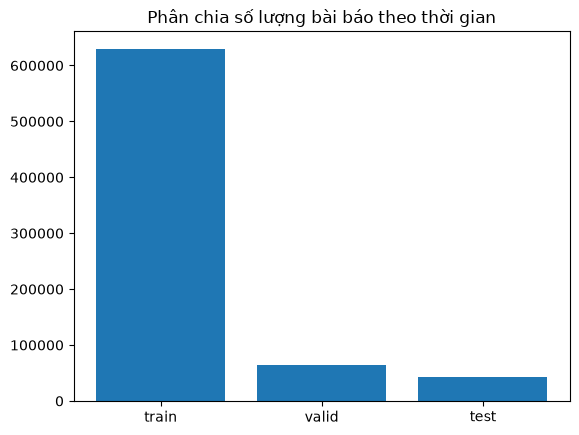

In [43]:
cot_1 = ["train", "valid", "test"]
cot_2 = [df_train.count(), df_valid.count(), df_test.count()]

plt.bar(cot_1, cot_2)
plt.title("Phân chia số lượng bài báo theo thời gian")
plt.show()

## 6. Phân Tích Bậc Ra (Out-Degree - Số Tài Liệu Tham Khảo Của Mỗi Bài Báo)
- **Bậc ra (Out-degree):** Số lượng tài liệu tham khảo mà một bài báo trỏ tới.
- **Ý nghĩa:** Kiểm tra trung bình một bài báo tham khảo bao nhiêu công trình khoa học.

In [44]:
bac_ra_1 = df_clean.groupBy("src").count().withColumnRenamed("count", "bac_ra")
bac_ra_1.describe().show()

+-------+------------------+------------------+
|summary|               src|            bac_ra|
+-------+------------------+------------------+
|  count|            617924|            617924|
|   mean| 388979.1321926321| 8.765270486338126|
| stddev|216650.11911799075|11.332959937801725|
|    min|                 0|                 1|
|    max|            736388|               609|
+-------+------------------+------------------+



## 7. Kiểm Tra Tính Toàn Vẹn Của Đồ Thị (Cạnh Trùng Lặp & Self-Loops)
- **Duplicate edges:** Kiểm tra xem có cặp trích dẫn nào bị ghi nhận 2 lần không.
- **Self-loops (`src == dst`):** Kiểm tra xem có bài báo nào tự trích dẫn chính nó trong cùng một cạnh không.

In [45]:
total_edges = df_clean.count()
distinct_edges = df_clean.distinct().count()

duplicate = total_edges - distinct_edges
print(f"Tổng số bài báo trích xuất trùng lặp: {duplicate}")

Tổng số bài báo trích xuất trùng lặp: 0


In [46]:
self_edges = df_clean.filter(col("src") == col("dst")).count()

print(f"Số bài báo tự trích xuất chính bài báo đó: {self_edges}")

Số bài báo tự trích xuất chính bài báo đó: 0


## 8. Kiểm Tra Đỉnh Cô Lập (Isolated Nodes)
- **Isolated node:** Bài báo không trích dẫn ai và cũng không được ai trích dẫn trong đồ thị.

In [47]:
tong_so_bai = df_train.count() + df_valid.count() + df_test.count()

co_lien_ket = df_clean.select("src").union(df_clean.select("dst")).distinct().count()

co_lap = tong_so_bai - co_lien_ket
print(f"Tổng số bài: {tong_so_bai}")
print(f"Số bài báo có liên kết trích dẫn: {co_lien_ket}")
print(f"Số bài báo bị cô lập: {co_lap}")

Tổng số bài: 736389
Số bài báo có liên kết trích dẫn: 736389
Số bài báo bị cô lập: 0


## 9. Ánh Xạ Chỉ Mục Thực Thể (Entity Index to Original ID/Name)
- **Mục đích:** Tra cứu từ số nguyên nội bộ của đồ thị sang ID gốc trong Microsoft Academic Graph (MAG) cho Bài báo, Tác giả, Lĩnh vực và Viện trường.

In [48]:
paper_id_to_name = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/mapping/paper_entidx2name.csv.gz"

df_map = spark.read.csv(paper_id_to_name, header=False)

df_map.show(5)

+-------+--------+
|    _c0|     _c1|
+-------+--------+
|ent idx|ent name|
|      0|   24982|
|      1|  274683|
|      2|  539484|
|      3|  584818|
+-------+--------+
only showing top 5 rows


In [49]:
author_id_to_name = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/mapping/author_entidx2name.csv.gz"

df_map = spark.read.csv(author_id_to_name, header=False)

df_map.show(5)

+-------+--------+
|    _c0|     _c1|
+-------+--------+
|ent idx|ent name|
|      0|   29650|
|      1|   39382|
|      2|   41399|
|      3|   46586|
+-------+--------+
only showing top 5 rows


In [50]:
field_of_study_to_name = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/mapping/field_of_study_entidx2name.csv.gz"

df_map = spark.read.csv(field_of_study_to_name, header=False)

df_map.show(5)

+-------+--------+
|    _c0|     _c1|
+-------+--------+
|ent idx|ent name|
|      0|    4250|
|      1|   12843|
|      2|   20288|
|      3|   37253|
+-------+--------+
only showing top 5 rows


In [51]:
institution_to_name = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/mapping/institution_entidx2name.csv.gz"

df_map = spark.read.csv(institution_to_name, header=False)

df_map.show(5)

+-------+--------+
|    _c0|     _c1|
+-------+--------+
|ent idx|ent name|
|      0|    9507|
|      1|   19722|
|      2|   41870|
|      3|   43886|
+-------+--------+
only showing top 5 rows


## 10. Khảo Sát Đặc Trưng Ngữ Nghĩa (128-Dimensional Semantic Embeddings)
- **File:** `node-feat.csv.gz` gồm đúng 736.389 dòng x 128 cột số thực.
- **Nguồn gốc:** Vector Word2Vec được Stanford OGB trích xuất từ tiêu đề và tóm tắt bài báo.
- **Vai trò:** Giúp mô hình hiểu nội dung khoa học ngay cả khi bài báo mới ra mắt chưa có trích dẫn.

In [52]:
path = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/nodetype-has-feat.csv.gz"
node = spark.read.csv(path)
node.show(5)

+-----+------+-----------+--------------+
|  _c0|   _c1|        _c2|           _c3|
+-----+------+-----------+--------------+
|paper|author|institution|field_of_study|
| True| False|      False|         False|
+-----+------+-----------+--------------+



In [53]:
feat_path = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/node-feat/paper/node-feat.csv.gz"
df_feat = spark.read.csv(feat_path, header=False, inferSchema=True)
print("Số bài báo:", df_feat.count())
print("Số chiều đặc trưng:", len(df.columns))

Số bài báo: 736389
Số chiều đặc trưng: 2


In [54]:
print(df_feat.show(5))

+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+--------+---------+---------+--------+---------+--------+--------+---------+---------+--------+---------+---------+---------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+---------+--------+---------+--------+---------+--------+---------+--------+--------+--------+--------+---------+---------+---------+---------+---------+---------+---------+---------+--------+---------+---------+---------+---------+--------+---------+--------+--------+---------+---------+---------+--------+---------+---------+---------+---------+--------+---------+---------+---------+---------+--------+---------+---------+--------+---------+--------+--------+---------+--------+---------+--------+---------+--------+---------+---------+---------+--------+---------+---------+--------+--------

26/10/10 10:29:15 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


## 11. Phân Phối Bài Báo Theo Năm Xuất Bản (Publication Year Distribution)
- **File:** `node_year.csv.gz` chứa năm xuất bản của từng bài báo (từ năm 2010 đến 2019).
- **Ý nghĩa:** Trực quan hóa số lượng bài báo tăng trưởng theo từng năm.

In [56]:
from pyspark.sql import functions as F

path = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/node-feat/paper/node_year.csv.gz"
node = spark.read.csv(path).toDF("year").withColumn("year", F.col("year").cast("int"))
node.distinct().orderBy("year").show()

+----+
|year|
+----+
|2010|
|2011|
|2012|
|2013|
|2014|
|2015|
|2016|
|2017|
|2018|
|2019|
+----+



In [57]:
node = spark.read.csv(path).toDF("year").withColumn("year", F.col("year").cast("int"))
node.groupBy("year").count().orderBy("year").show()

+----+-----+
|year|count|
+----+-----+
|2010|73553|
|2011|78313|
|2012|82673|
|2013|84890|
|2014|83169|
|2015|79659|
|2016|77116|
|2017|70198|
|2018|64879|
|2019|41939|
+----+-----+



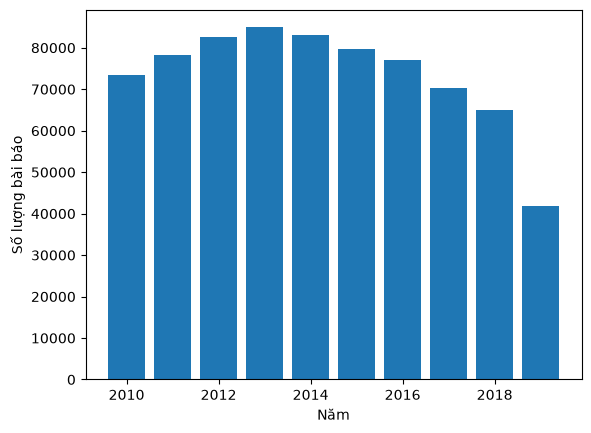

In [58]:
import matplotlib.pyplot as plt 
df = node.groupBy("year").count().orderBy("year").toPandas()
plt.bar(df["year"], df["count"])
plt.xlabel("Năm")
plt.ylabel("Số lượng bài báo")
plt.show()

## 12. Phân Tích Quan Hệ Đồ Thị Không Đồng Nhất: Tác Giả Viết Bài Báo (Author writes Paper)
- **File:** `author___writes___paper/edge.csv.gz`.
- **Ý nghĩa:** Cột `_c0` là `author_id`, `_c1` là `paper_id`. Dùng để đếm quy mô nhóm tác giả cho mỗi bài báo.

In [61]:
path_author_paper = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/relations/author___writes___paper/edge.csv.gz"
df_author_paper = spark.read.csv(path_author_paper, header=False).toDF("author_id", "paper_id")
df_author_paper.show(5)


+---------+--------+
|author_id|paper_id|
+---------+--------+
|        0|   19703|
|        0|  289285|
|        0|  311768|
|        0|  402711|
|        1|  181505|
+---------+--------+
only showing top 5 rows


## 13. Phân Tích Lĩnh Vực Nghiên Cứu (Paper has Topic)
- Khảo sát số lượng chủ đề khoa học trên mỗi bài báo (Đặc trưng tính liên ngành).

In [ ]:
path_topic = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/relations/paper___has_topic___field_of_study/edge.csv.gz"
df_paper_topic = spark.read.csv(path_topic, header=False).toDF("paper_id", "topic_id")

df_topic_count = df_paper_topic.groupBy("paper_id").count().withColumnRenamed("count", "num_topics")
df_topic_count.describe().show()

+-------+------------------+------------------+
|summary|          paper_id|        num_topics|
+-------+------------------+------------------+
|  count|            736389|            736389|
|   mean|          368194.0|10.191730186083714|
| stddev|212577.33802665793|1.5646850294509684|
|    min|                 0|                 1|
|    max|             99999|                14|
+-------+------------------+------------------+



## 14. Phân Tích Viện Nghiên Cứu & Trường Đại Học (Author Affiliation)
- Khảo sát tổ chức công tác của các tác giả.

In [63]:
path_inst = "/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/mag/raw/relations/author___affiliated_with___institution/edge.csv.gz"
df_author_inst = spark.read.csv(path_inst, header=False).toDF("author_id", "institution_id")
print("Tổng số liên kết tác giả - viện trường:", df_author_inst.count())
df_author_inst.show(5)

Tổng số liên kết tác giả - viện trường: 1043998
+---------+--------------+
|author_id|institution_id|
+---------+--------------+
|        0|           845|
|        1|           996|
|        2|          3197|
|        2|          6133|
|        2|          6744|
+---------+--------------+
only showing top 5 rows


## 15. Phân Tích Độ Trễ Trích Dẫn (Citation Lag & Aging Dynamics)
- Tính `lag = năm_trích_dẫn - năm_xuất_bản` để quan sát quy luật lão hóa theo thời gian.

In [ ]:
df_years_clean = node.withColumnRenamed("year", "pub_year").withColumn("paper_id", F.monotonically_increasing_id())

edges_timed = df_clean \
    .join(df_years_clean.select(F.col("paper_id").alias("src"), F.col("pub_year").alias("src_year")), on="src") \
    .join(df_years_clean.select(F.col("paper_id").alias("dst"), F.col("pub_year").alias("dst_year")), on="dst") \
    .withColumn("citation_lag", F.col("src_year") - F.col("dst_year"))

lag_distribution = edges_timed.filter(F.col("citation_lag") >= 0).groupBy("citation_lag").count().orderBy("citation_lag")
lag_distribution.show(10)

+------------+-------+
|citation_lag|  count|
+------------+-------+
|           0| 509025|
|           1|1185686|
|           2|1070769|
|           3| 832987|
|           4| 629454|
|           5| 460370|
|           6| 326009|
|           7| 207667|
|           8| 116479|
|           9|  44117|
+------------+-------+



## 16. Tính Tăng Trưởng Trích Dẫn Tương Lai (Delta_C) & Ngưỡng Bùng Nổ P95
- Tính số trích dẫn bài báo năm 2018 nhận thêm ở năm 2019 và tìm điểm cắt phân vị 95%.

In [65]:
# Trích dẫn năm 2019 trỏ tới các bài báo xuất bản năm 2018
future_cites_2018 = edges_timed.filter((F.col("dst_year") == 2018) & (F.col("src_year") == 2019)) \
    .groupBy("dst").agg(F.count("src").alias("delta_c"))

# Tính ngưỡng phân vị 95% (P95)
p95_val = future_cites_2018.approxQuantile("delta_c", [0.95], 0.001)[0]
print(f"Ngưỡng bùng nổ phân vị 95% (P95): {p95_val} trích dẫn mới")

Ngưỡng bùng nổ phân vị 95% (P95): 10.0 trích dẫn mới


## 17. Đóng Gói Vector Ngữ Nghĩa 128 Chiều (VectorAssembler)
- Gom 128 cột số thực thành 1 cột vector duy nhất để đưa vào mô hình Machine Learning.

In [66]:
from pyspark.ml.feature import VectorAssembler

feat_cols = [f"_c{i}" for i in range(128)]
assembler = VectorAssembler(inputCols=feat_cols, outputCol="node_feat_128d")

# Chuyển đổi sang cột vector
df_feat_vector = assembler.transform(df_feat).select("node_feat_128d")
df_feat_vector.show(2, truncate=50)

+--------------------------------------------------+
|                                    node_feat_128d|
+--------------------------------------------------+
|[-0.095379,0.040758,-0.210948,-0.064362,-0.2259...|
|[-0.151047,-0.107315,-0.221964,-0.034725,0.0108...|
+--------------------------------------------------+
only showing top 2 rows
